# Attaching **SMS `.dat`** results to a mesh — the `needs_mesh` pattern

Some formats store **only values, no topology**. The SMS ASCII **`.dat`** dataset is one: it lists a scalar (or vector) per node or per cell, for one or more time steps, but says nothing about where the nodes are. A file like that is useless on its own — it needs a mesh to hang the numbers on.

`pyramids-mesh` models this with the **`needs_mesh`** capability. A `needs_mesh` driver does not implement `read` (it cannot build a mesh); it implements `read_data`, reached through **`UgridDataset.read_file(mesh).attach_data(results)`**. You read the geometry from a mesh file first, then *attach* the results onto it. This notebook reads `minimal.2dm` for the topology and attaches the matching `minimal.dat` depth series.

## 3. Locate the data

Two files, same folder: the mesh (`minimal.2dm`) and the results (`minimal.dat`). Both paths are relative to this notebook.

In [1]:
from pathlib import Path
DATA = Path("../../examples/data")
print("mesh   :", (DATA / "minimal.2dm").resolve())
print("results:", (DATA / "minimal.dat").resolve())

mesh   : C:\python-environments\worktrees\pyramids-mesh\example-notebooks\examples\data\minimal.2dm
results: C:\python-environments\worktrees\pyramids-mesh\example-notebooks\examples\data\minimal.dat


## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import matplotlib.pyplot as plt

## 4. Read the mesh, then attach the data

Step one reads the **topology** from the 2DM file. Step two calls `attach_data()` with the `.dat` path: the `needs_mesh` driver reads the per-node values and binds them onto the mesh we already hold, returning a new `UgridDataset`. Note what happens to the variable list — the `depth` series from the `.dat` appears alongside the mesh's own `material`/`node_z`.

In [3]:
mesh_ds = UgridDataset.read_file(DATA / "minimal.2dm", driver="2dm")
print("before attach:", mesh_ds.data_variable_names)
ds = mesh_ds.attach_data(DATA / "minimal.dat")
print("after attach :", ds.data_variable_names)

before attach: ['material', 'node_z']
after attach : ['material', 'node_z', 'depth']


In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

`depth` is now part of the dataset. If you tried to `read_file` the `.dat` directly the driver would raise, pointing you at exactly this `read_file(mesh).attach_data(dat)` idiom — that is the `needs_mesh` contract made visible.

## 5. Explore the attached dataset

The `depth` variable spans two time steps (its `count` is `2 x n_node`). `summary()` shows its range; the mesh-side variables remain uniform on this minimal square.

In [5]:
print('nodes :', ds.n_node, ' faces:', ds.n_face)
print('vars  :', ds.data_variable_names)
print('crs   :', ds.crs, ' epsg:', ds.epsg)

nodes : 4  faces: 2
vars  : ['material', 'node_z', 'depth']
crs   : None  epsg: None


In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
material,2,1.0,1.0,1.00,0.000000
node_z,4,0.0,0.0,0.00,0.000000
depth,8,0.5,1.8,1.15,0.512348


### Provenance

`attach_data` keeps the mesh's own global attributes and does not let the results file overwrite them, so the dataset still reads as an SMS 2DM mesh.

In [7]:
ds.global_attributes

{'Conventions': 'UGRID-1.0', 'source': 'SMS 2DM'}

## 6. The `Mesh2d` geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the face-node connectivity table. `face_node_connectivity.data` has shape `(n_face, k)` — row *i* lists the node indices of face *i* (padded for mixed element types). We also derive per-face areas and centroids from that topology.

In [8]:
m = ds.mesh
print('node_x shape           :', m.node_x.shape)
print('connectivity shape     :', m.face_node_connectivity.data.shape)
print('face_areas shape       :', m.face_areas.shape)
centroids = np.asarray(m.face_centroids)  # shape (2, n_face)
print('face_centroids shape   :', centroids.shape)
print('first face areas       :', m.face_areas[:3])

node_x shape           : (4,)
connectivity shape     : (2, 3)
face_areas shape       : (2,)
face_centroids shape   : (2, 2)
first face areas       : [0.5 0.5]


## 7. Wireframe — the mesh skeleton

`plot_outline()` draws the bare mesh: every face edge, no data coloring. This is the fastest way to eyeball connectivity, element shapes and the overall extent.

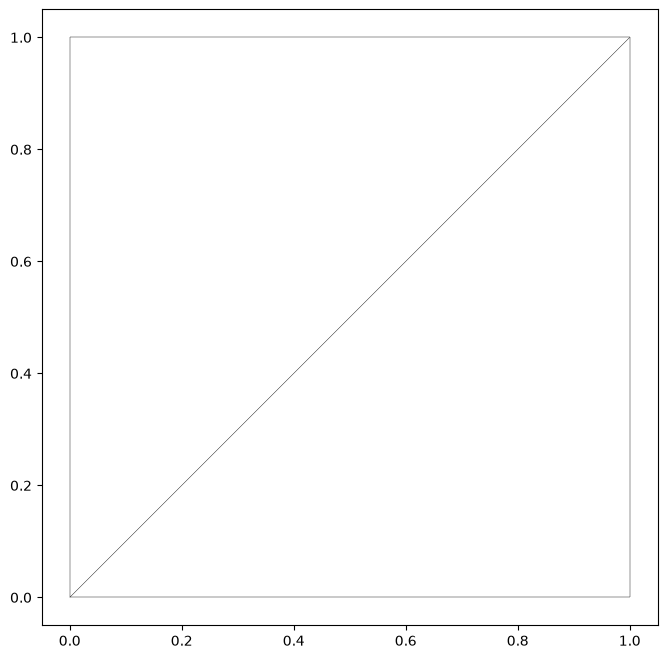

In [9]:
ds.plot_outline()


## 8. A data map

Now the payoff: we map the **attached** `depth` field. These are the numbers from the `.dat` file, drawn on the geometry from the `.2dm` file — the two halves joined by `attach_data`. `plot` shows the first time step by default.

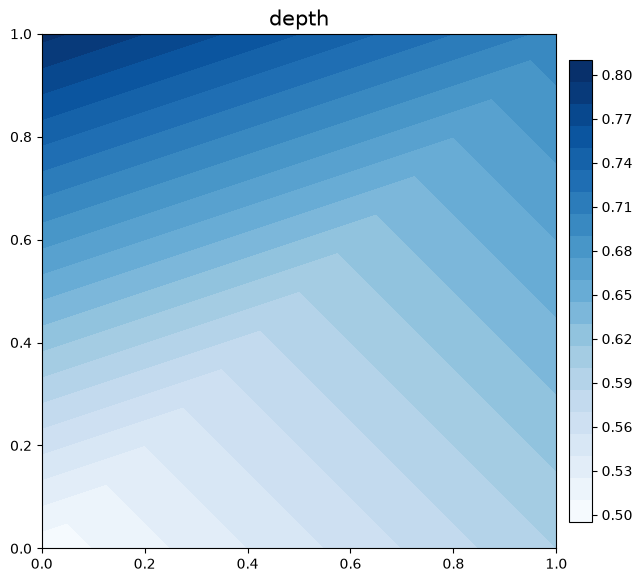

In [10]:
ds.plot('depth', cmap='Blues', colorbar=True, title='depth')


## 9. GIS operations

Because a `UgridDataset` is a first-class `pyramids` object, the full geospatial toolkit works on it directly — no conversion step. Below are several operations, each visualised or interpreted. (Operations that need a source CRS, such as `to_crs`, are skipped here: this sample declares none.)

### 9a. Faces as polygons — `to_geodataframe()`

Every face becomes a shapely polygon in a GeoPandas `GeoDataFrame`, ready for a spatial join, an overlay, or export to any OGR vector format.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((0 0, 1 0, 1 1, 0 0))"
1,"POLYGON ((0 0, 1 1, 0 1, 0 0))"


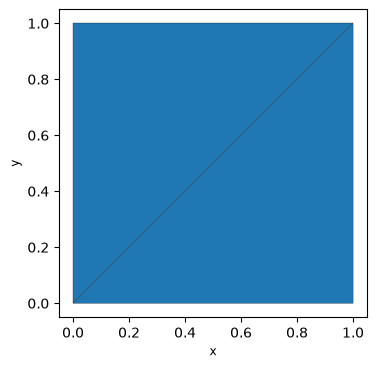

In [12]:
gdf.plot(edgecolor="k", linewidth=0.2, figsize=(5, 4))
plt.gca().set_aspect("equal")


The polygon mosaic is the mesh itself — each cell is now an independent vector feature. That is the bridge from a solver mesh to standard GIS.

### 9b. Outer boundary — `bounding_polygon()` and `exterior_edges()`

`bounding_polygon()` dissolves the faces into a single shapely polygon tracing the mesh outline, and `exterior_edges()` returns the indices of the mesh edges that lie on that boundary — their count is the boundary's edge length.

boundary edges: 4


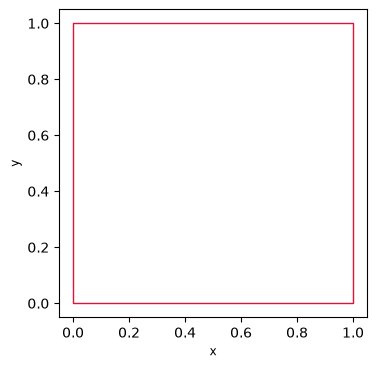

In [13]:
poly = ds.bounding_polygon()
n_boundary = len(ds.exterior_edges())
print('boundary edges:', n_boundary)
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 4))
plt.gca().set_aspect("equal")


The crimson ring is the domain outline; `exterior_edges()` tells us how many element edges trace it — the rest of the edges are interior.

### 9c. Connectivity — `connected_components()`

`connected_components()` labels each face by the connected sub-mesh it belongs to. One unique label means the mesh is a single watertight piece; more than one would reveal detached islands. We attach the labels as a face variable and map them.

faces: 2  components: 1


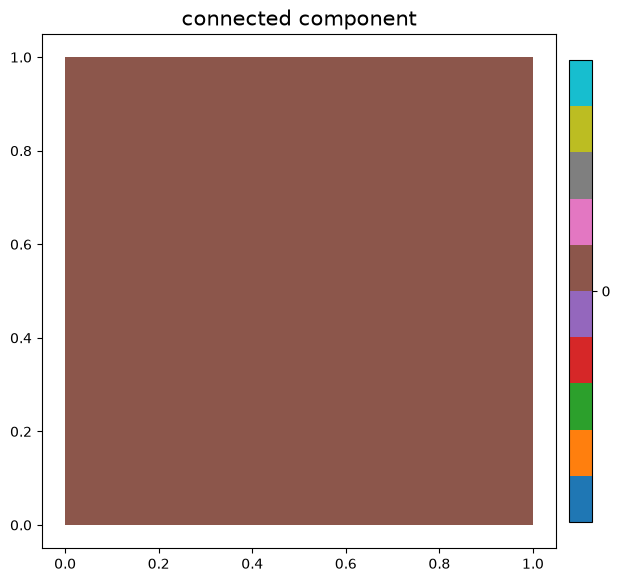

In [14]:
comp = ds.connected_components()
print('faces:', comp.size, ' components:', len(np.unique(comp)))
dc = ds.with_variable("component", comp.astype(float), location="face")
dc.plot("component", cmap="tab10", colorbar=True, title="connected component")


### 9d. Face adjacency — `sparse_adjacency()`

`sparse_adjacency()` returns the face-to-face adjacency as a SciPy sparse matrix (two faces are adjacent when they share an edge). Its sparsity pattern is the dual graph a solver walks; `nnz` counts the directed face-neighbour links.

shape: (2, 2)  nnz: 2


Text(0.5, 1.0, 'face adjacency')

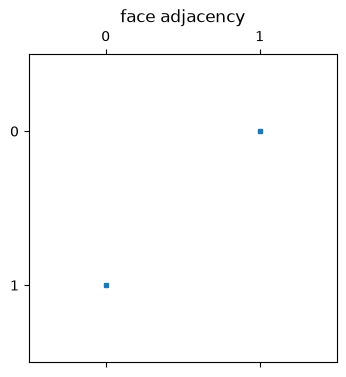

In [15]:
adj = ds.sparse_adjacency()
print('shape:', adj.shape, ' nnz:', adj.nnz)
plt.figure(figsize=(4, 4))
plt.spy(adj, markersize=3)
plt.title("face adjacency")


### 9e. Triangle circumcenters — `circumcenters()`

For a triangular mesh, `circumcenters()` returns the circumcircle centre of each face (shape `(2, n_face)`) — the sample points of the dual Voronoi mesh that finite-volume schemes use. We scatter them over the wireframe.

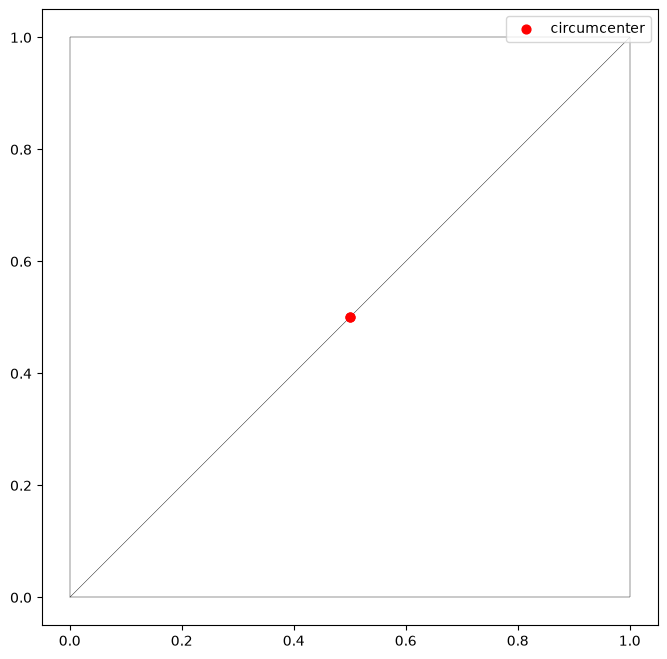

In [16]:
cc = ds.circumcenters()
ds.plot_outline()
plt.scatter(cc[0], cc[1], c="red", s=40, zorder=5, label="circumcenter")
plt.legend()


### 9f. Clip to a sub-region — `crop()`

`crop(bbox=...)` keeps the faces inside a box; the attached `depth` values ride along with the clipped mesh.

faces after crop: 0 of 2


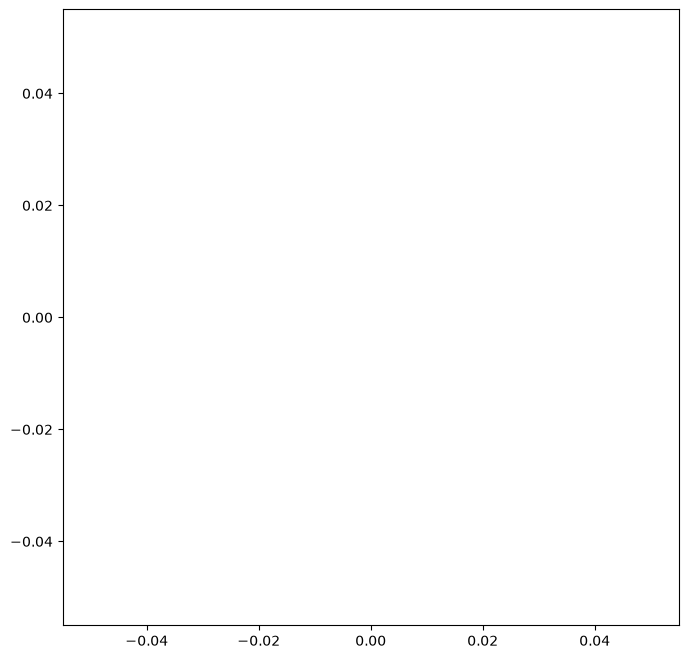

In [17]:
b = ds.bounds
sub = ds.crop(bbox=(b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2))
print('faces after crop:', sub.n_face, 'of', ds.n_face)
sub.plot_outline()


### 9g. Round-trip through UGRID NetCDF — `to_file()` / `to_xarray()`

`to_file(..., driver='ugrid')` writes the mesh to the CF/UGRID NetCDF convention — the lossless lingua franca every tool in the stack reads back. We write it, re-read it, and confirm the topology survived. `to_xarray()` hands the same content to the xarray ecosystem in memory.

In [18]:
import tempfile
out = Path(tempfile.mkdtemp()) / 'roundtrip.nc'
ds.to_file(out, driver="ugrid")
back = UgridDataset.read_file(out, driver="ugrid")
print('re-read nodes/faces:', back.n_node, back.n_face)
ds.to_xarray()

re-read nodes/faces: 4 2


<xarray.Dataset> Size: 228B
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 4, mesh2d_nFaces: 2,
                        mesh2d_nMaxFaceNodes: 3, n_face: 2, time: 2, n_node: 4)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes, n_face, time, n_node
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 32B 0.0 1.0 1.0 0.0
    mesh2d_node_y      (mesh2d_nNodes) float64 32B 0.0 0.0 1.0 1.0
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 48B 1 2 ... 4
    material           (n_face) float64 16B 1.0 1.0
    node_z             (mesh2d_nNodes) float64 32B 0.0 0.0 0.0 0.0
    depth              (time, n_node) float64 64B 0.5 0.6 0.7 ... 1.6 1.7 1.8
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

## 10. Takeaway

Results-only formats declare **`needs_mesh`**: you read a mesh, then `attach_data()` the values onto it. The same pattern powers the XMDF and other solver-output readers. Once attached, the field is an ordinary data variable — mappable, clippable and exportable like any other.